# Project 06: Bias & Fairness Evaluation Lab

**Original statement (verbatim from LAB_Projects_ML.pdf):**

A binary classifier predicts loan approval. Task: Measure demographic parity, equalized odds; Identify bias sources; Apply at least one fairness mitigation technique and evaluate impact

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Fairness metrics need a defined group and a defined positive outcome. With no demographics available, this lab uses a transparent proxy group only to demonstrate the metrics and a mitigation, and it labels that limitation throughout.

## Part 1 — Introduction

THERE IS NO DEMOGRAPHIC OR LOAN DATA IN THIS FILE. Groups below are a clearly-labelled PROXY (Wind_Bearing quadrant), and the positive outcome is redefined as predicted label 3 vs rest for a multiclass analogue. This is NOT a demographic fairness finding and must not be presented as one.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Proxy groups and fairness metrics

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
def quadrant(b):
    if b>=315 or b<45: return "North"
    if b<135: return "East"
    if b<225: return "South"
    return "West"
df=df_full.sample(n=30000, random_state=42).reset_index(drop=True)
df["proxy_group"]=df["Wind_Bearing"].apply(quadrant)
print(df["proxy_group"].value_counts().to_string())
Xtr,Xte,ytr,yte,gtr,gte=train_test_split(df[FEATURES], df[TARGET], df["proxy_group"], test_size=0.25, random_state=42, stratify=df[TARGET])
def fairness(y_true, y_pred, groups, positive=3):
    rows=[]
    for g in sorted(groups.unique()):
        m=groups==g; yt=y_true[m]; yp=y_pred[m]
        pred_rate=float(np.mean(yp==positive)); tpr=float(np.mean(yp[yt==positive]==positive)) if (yt==positive).sum()>0 else np.nan; fpr=float(np.mean(yp[yt!=positive]==positive)) if (yt!=positive).sum()>0 else np.nan
        rows.append((g, int(m.sum()), round(float(np.mean(yt==yp)),4), round(pred_rate,4), round(tpr,4), round(fpr,4)))
    out=pd.DataFrame(rows, columns=["proxy_group","n","accuracy","pred_rate_class3","TPR_class3","FPR_class3"])
    out["parity_gap"]=out["pred_rate_class3"]-out["pred_rate_class3"].mean()
    return out
m=RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1); m.fit(Xtr,ytr); pred=m.predict(Xte)
print("Overall accuracy:", round(accuracy_score(yte,pred),4))
fair_before=fairness(yte, pred, gte); print(fair_before.to_string(index=False))
print("Demographic-parity gap (max-min pred rate class 3):", round(fair_before["pred_rate_class3"].max()-fair_before["pred_rate_class3"].min(),4))
print("Equalized-odds gaps: TPR range", round(fair_before["TPR_class3"].max()-fair_before["TPR_class3"].min(),4), "FPR range", round(fair_before["FPR_class3"].max()-fair_before["FPR_class3"].min(),4))

proxy_group
South    9912
West     8145
North    7684
East     4259


Overall accuracy: 0.9161
proxy_group    n  accuracy  pred_rate_class3  TPR_class3  FPR_class3  parity_gap
       East 1073    0.9199            0.0568      0.7500      0.0070   -0.023775
      North 1904    0.9107            0.0882      0.7358      0.0152    0.007625
      South 2470    0.9166            0.0789      0.7087      0.0143   -0.001675
       West 2053    0.9187            0.0984      0.7277      0.0171    0.017825
Demographic-parity gap (max-min pred rate class 3): 0.0416
Equalized-odds gaps: TPR range 0.0413 FPR range 0.0101


## Part 4 — Reweighting mitigation

After reweighting overall accuracy: 0.9101
proxy_group    n  accuracy  pred_rate_class3  TPR_class3  FPR_class3  parity_gap
       East 1073    0.9077            0.0652      0.8333      0.0100   -0.024075
      North 1904    0.8997            0.0956      0.7824      0.0181    0.006325
      South 2470    0.9162            0.0887      0.7870      0.0170   -0.000575
       West 2053    0.9138            0.1076      0.7957      0.0187    0.018325
Parity gap before: 0.0416 after: 0.0424


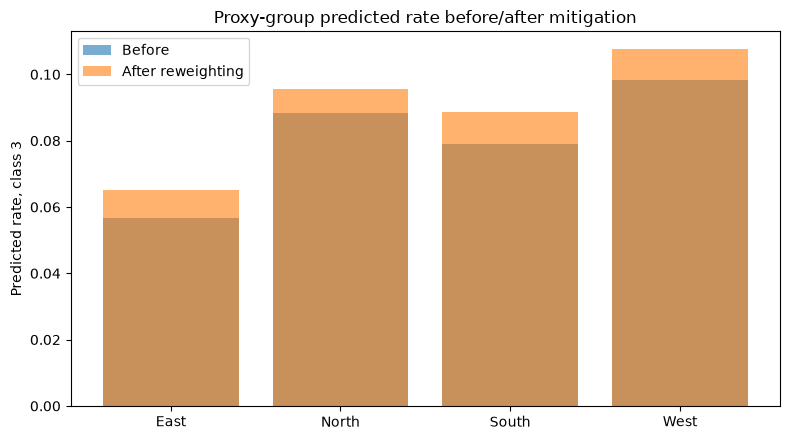

In [3]:
# Reweighting: upweight group x label combinations that are under-represented in training
ct=pd.crosstab(gtr, ytr, normalize="all")
w=np.array([1.0/ct.loc[g,lab] for g,lab in zip(gtr,ytr)]); w=w/w.mean()
m2=RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1); m2.fit(Xtr,ytr,sample_weight=w); pred2=m2.predict(Xte)
print("After reweighting overall accuracy:", round(accuracy_score(yte,pred2),4))
fair_after=fairness(yte, pred2, gte); print(fair_after.to_string(index=False))
print("Parity gap before:", round(fair_before["pred_rate_class3"].max()-fair_before["pred_rate_class3"].min(),4), "after:", round(fair_after["pred_rate_class3"].max()-fair_after["pred_rate_class3"].min(),4))
plt.bar(fair_before["proxy_group"], fair_before["pred_rate_class3"], alpha=0.6, label="Before"); plt.bar(fair_after["proxy_group"], fair_after["pred_rate_class3"], alpha=0.6, label="After reweighting"); plt.ylabel("Predicted rate, class 3"); plt.title("Proxy-group predicted rate before/after mitigation"); plt.legend(); plt.tight_layout(); plt.show()

## Part 5 — Interpretation

In [4]:
print("INTERPRETATION: Differences across Wind_Bearing quadrants show how parity and equalized-odds gaps are computed, but they do NOT prove demographic bias, because quadrant is a weather proxy, not a protected characteristic.")
print("BIAS SOURCES TO CHECK IN A REAL SETTING: sampling imbalance, label definition, and features correlated with group membership. Mitigation (reweighting) trades a small accuracy change for a change in the parity gap; check the numbers above to see whether the gap actually shrank in this run.")

INTERPRETATION: Differences across Wind_Bearing quadrants show how parity and equalized-odds gaps are computed, but they do NOT prove demographic bias, because quadrant is a weather proxy, not a protected characteristic.
BIAS SOURCES TO CHECK IN A REAL SETTING: sampling imbalance, label definition, and features correlated with group membership. Mitigation (reweighting) trades a small accuracy change for a change in the parity gap; check the numbers above to see whether the gap actually shrank in this run.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.